# Phase 1 — Data Inspection & Understanding

This notebook only inspects and documents the two original datasets. It does not merge, fill, encode, drop, or train anything.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

## 2. Load the Datasets

The original CSV files are read without modification.

In [2]:
from pathlib import Path

project = Path.cwd().parent
transaction_path = project / "data" / "raw" / "train_transaction.csv"
identity_path = project / "data" / "raw" / "train_identity.csv"

train_transaction = pd.read_csv(transaction_path, low_memory=False)
train_identity = pd.read_csv(identity_path, low_memory=False)

print("Transaction file:", transaction_path)
print("Identity file:", identity_path)
print("Original files were not modified.")

Transaction file: C:\Users\HP\Desktop\fraud-detection-system\data\raw\train_transaction.csv
Identity file: C:\Users\HP\Desktop\fraud-detection-system\data\raw\train_identity.csv
Original files were not modified.


## 3. Basic Dataset Information

**What was checked?** Shape, first and last rows, data types, and memory usage.

**Meaning:** These checks establish the size and structure before any later processing.

**Decision:** Do not modify the datasets at this stage.

In [3]:
for name, df in [("train_transaction", train_transaction), ("train_identity", train_identity)]:
    print("\n=====", name, "=====")
    print("Shape:", df.shape)
    print("Head:")
    display(df.head())
    print("Tail:")
    display(df.tail())
    print("Data types:")
    display(df.dtypes.value_counts())
    print("Memory usage:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")


===== train_transaction =====
Shape: (590540, 394)
Head:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Tail:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
590535,3577535,0,15811047,49.00,W,6550,NaN,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590536,3577536,0,15811049,39.50,W,10444,225.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590537,3577537,0,15811079,30.95,W,12037,595.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590538,3577538,0,15811088,117.00,W,7826,481.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
590539,3577539,0,15811131,279.95,W,15066,170.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Data types:


float64    376
str         14
int64        4
Name: count, dtype: int64

... (3 outputs left out)

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
144228,3577521,-15.0,145955.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 66.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,F3111 Build/33.3.A.1.97
144229,3577526,-5.0,172059.0,NaN,NaN,1.0,-5.0,NaN,NaN,NaN,...,chrome 55.0 for android,32.0,855x480,match_status:2,T,F,T,F,mobile,A574BL Build/NMF26F
144230,3577529,-20.0,632381.0,NaN,NaN,-1.0,-36.0,NaN,NaN,NaN,...,chrome 65.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,Moto E (4) Plus Build/NMA26.42-152
144231,3577531,-5.0,55528.0,0.0,0.0,0.0,-7.0,NaN,NaN,0.0,...,chrome 66.0,24.0,2560x1600,match_status:2,T,F,T,F,desktop,MacOS
144232,3577534,-45.0,339406.0,NaN,NaN,-10.0,-100.0,NaN,NaN,NaN,...,chrome 66.0 for android,NaN,NaN,NaN,F,F,T,F,mobile,RNE-L03 Build/HUAWEIRNE-L03


Data types:


float64    23
str        17
int64       1
Name: count, dtype: int64

Memory usage: 56.51 MB


In [4]:
summary = pd.DataFrame({
    "Dataset": ["train_transaction", "train_identity"],
    "Rows": [len(train_transaction), len(train_identity)],
    "Columns": [len(train_transaction.columns), len(train_identity.columns)]
})
display(summary)

,Dataset,Rows,Columns
0,train_transaction,590540,394
1,train_identity,144233,41


## 4. Transaction Dataset Analysis

### 4.1 Column Names and Types

All column names are available through `train_transaction.columns`. A compact grouped display keeps the notebook readable.

In [5]:
print("Transaction columns:")
for start in range(0, len(train_transaction.columns), 50):
    print(train_transaction.columns[start:start+50].tolist())

print("\nData types:")
display(train_transaction.dtypes.value_counts())
numerical_columns = train_transaction.select_dtypes(include=np.number).columns.tolist()
categorical_columns = train_transaction.select_dtypes(include=["object", "category"]).columns.tolist()
boolean_columns = train_transaction.select_dtypes(include="bool").columns.tolist()
print("Numerical:", len(numerical_columns))
print("Categorical/Object:", len(categorical_columns))
print("Boolean:", len(boolean_columns))

Transaction columns:
['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4']
['M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45']
['V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 

float64    376
str         14
int64        4
Name: count, dtype: int64

Numerical: 380
Categorical/Object: 14
Boolean: 0


C:\Users\HP\AppData\Local\Temp\ipykernel_24364\675546385.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = train_transaction.select_dtypes(include=["object", "category"]).columns.tolist()


### 4.2 Numerical and Categorical Features

In [6]:
print("Numerical statistics:")
display(train_transaction[numerical_columns].describe().T.head(20))

print("Categorical columns:", categorical_columns)
for column in categorical_columns:
    print("\n", column, "unique values:", train_transaction[column].nunique(dropna=False))
    display(train_transaction[column].value_counts(dropna=False).head(10))

Numerical statistics:


,count,mean,std,min,25%,50%,75%,max
TransactionID,590540.0,3.282270e+06,1.704744e+05,2987000.000,3134634.750,3282269.500,3429904.25,3.577539e+06
isFraud,590540.0,3.499001e-02,1.837546e-01,0.000,0.000,0.000,0.00,1.000000e+00
TransactionDT,590540.0,7.372311e+06,4.617224e+06,86400.000,3027057.750,7306527.500,11246620.00,1.581113e+07
TransactionAmt,590540.0,1.350272e+02,2.391625e+02,0.251,43.321,68.769,125.00,3.193739e+04
card1,590540.0,9.898735e+03,4.901170e+03,1000.000,6019.000,9678.000,14184.00,1.839600e+04
card2,581607.0,3.625555e+02,1.577932e+02,100.000,214.000,361.000,512.00,6.000000e+02
card3,588975.0,1.531949e+02,1.133644e+01,100.000,150.000,150.000,150.00,2.310000e+02
card5,586281.0,1.992789e+02,4.124445e+01,100.000,166.000,226.000,226.00,2.370000e+02
addr1,524834.0,2.907338e+02,1.017411e+02,100.000,204.000,299.000,330.00,5.400000e+02
addr2,524834.0,8.680063e+01,2.690623e+00,10.000,87.000,87.000,87.00,1.020000e+02


Categorical columns: ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']

 ProductCD unique values: 5


ProductCD
W    439670
C     68519
R     37699
H     33024
S     11628
Name: count, dtype: int64


 card4 unique values: 5


card4
visa                384767
mastercard          189217
american express      8328
discover              6651
NaN                   1577
Name: count, dtype: int64

... (20 outputs left out)


 M8 unique values: 3


M8
NaN    346252
F      155251
T       89037
Name: count, dtype: int64


 M9 unique values: 3


M9
NaN    346252
T      205656
F       38632
Name: count, dtype: int64

**Interpretation:** Numerical columns have different scales and ranges. Categorical columns have limited or moderate numbers of values. No encoding or type conversion is performed now.

## 5. Identity Dataset Analysis

In [7]:
identity_numerical = train_identity.select_dtypes(include=np.number).columns.tolist()
identity_categorical = train_identity.select_dtypes(include=["object", "category"]).columns.tolist()
print("Columns:", train_identity.columns.tolist())
print("Numerical columns:", len(identity_numerical))
print("Categorical/Object columns:", len(identity_categorical))
print("Identity numerical statistics:")
display(train_identity[identity_numerical].describe().T)

for column in ["DeviceInfo"] + [c for c in train_identity.columns if c.startswith("id_")]:
    if column in train_identity.columns:
        print("\n", column, "unique values:", train_identity[column].nunique(dropna=False))
        display(train_identity[column].value_counts(dropna=False).head(10))

Columns: ['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']
Numerical columns: 24
Categorical/Object columns: 17
Identity numerical statistics:


C:\Users\HP\AppData\Local\Temp\ipykernel_24364\786978725.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  identity_categorical = train_identity.select_dtypes(include=["object", "category"]).columns.tolist()


,count,mean,std,min,25%,50%,75%,max
TransactionID,144233.0,3.236329e+06,178849.571186,2987004.0,3077142.0,3198818.0,3392923.0,3577534.0
id_01,144233.0,-1.017050e+01,14.347949,-100.0,-10.0,-5.0,-5.0,0.0
id_02,140872.0,1.747166e+05,159651.816856,1.0,67992.0,125800.5,228749.0,999595.0
id_03,66324.0,6.018937e-02,0.598231,-13.0,0.0,0.0,0.0,10.0
id_04,66324.0,-5.893794e-02,0.701015,-28.0,0.0,0.0,0.0,0.0
id_05,136865.0,1.615585e+00,5.249856,-72.0,0.0,0.0,1.0,52.0
id_06,136865.0,-6.698710e+00,16.491104,-100.0,-6.0,0.0,0.0,0.0
id_07,5155.0,1.328535e+01,11.384207,-46.0,5.0,14.0,22.0,61.0
id_08,5155.0,-3.860039e+01,26.084899,-100.0,-48.0,-34.0,-23.0,0.0
id_09,74926.0,9.102314e-02,0.983842,-36.0,0.0,0.0,0.0,25.0



 DeviceInfo unique values: 1787


DeviceInfo
Windows                  47722
NaN                      25567
iOS Device               19782
MacOS                    12573
Trident/7.0               7440
rv:11.0                   1901
rv:57.0                    962
SM-J700M Build/MMB29K      549
SM-G610M Build/MMB29K      461
SM-G531H Build/LMY48B      410
Name: count, dtype: int64


 id_01 unique values: 77


... (71 outputs left out)


 id_37 unique values: 3


id_37
T      110452
F       30533
NaN      3248
Name: count, dtype: int64


 id_38 unique values: 3


id_38
F      73922
T      67063
NaN     3248
Name: count, dtype: int64

**Interpretation:** Identity and device fields contain substantial missingness and some high-cardinality values. They are recorded for later investigation; they are not removed or transformed in Phase 1.

## 6. Target Analysis

In [8]:
target_counts = train_transaction["isFraud"].value_counts(dropna=False)
target_percent = train_transaction["isFraud"].value_counts(normalize=True, dropna=False) * 100
print("Counts:")
display(target_counts)
print("Percentages:")
display(target_percent)
print("Total transactions:", len(train_transaction))
print("Legitimate (0):", int(target_counts.get(0, 0)))
print("Fraud (1):", int(target_counts.get(1, 0)))
print("Observed values:", sorted(train_transaction["isFraud"].dropna().unique().tolist()))

Counts:


isFraud
0    569877
1     20663
Name: count, dtype: int64

Percentages:


isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Total transactions: 590540
Legitimate (0): 569877
Fraud (1): 20663


Observed values: [0, 1]


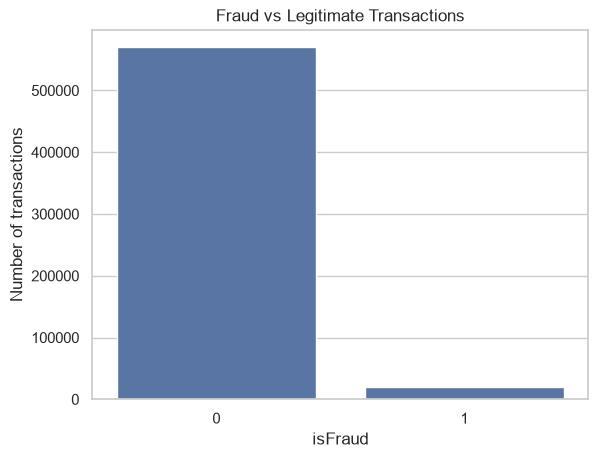

In [9]:
sns.countplot(x="isFraud", data=train_transaction)
plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("isFraud")
plt.ylabel("Number of transactions")
plt.show()

**Finding:** The target is binary with values 0 and 1. In this dataset, 0 represents legitimate transactions and 1 represents fraud, consistent with the dataset definition.

**Impact:** Fraud is the minority class, so later evaluation must not rely on accuracy alone. No imbalance method is applied now.

## 7. TransactionID Analysis

The datasets are not merged in this phase.

In [10]:
for name, df in [("Transaction", train_transaction), ("Identity", train_identity)]:
    print(name)
    print("Exists:", "TransactionID" in df.columns)
    print("Missing:", int(df["TransactionID"].isna().sum()))
    print("Unique:", int(df["TransactionID"].nunique()))
    print("Duplicates:", int(df["TransactionID"].duplicated().sum()))

transaction_ids = set(train_transaction["TransactionID"].dropna())
identity_ids = set(train_identity["TransactionID"].dropna())
common_ids = transaction_ids.intersection(identity_ids)
print("\nTransaction IDs:", len(transaction_ids))
print("Identity IDs:", len(identity_ids))
print("IDs in both:", len(common_ids))
print("Transaction IDs without identity:", len(transaction_ids - identity_ids))

Transaction
Exists: True
Missing: 0
Unique: 590540
Duplicates: 0
Identity
Exists: True
Missing: 0
Unique: 144233
Duplicates: 0



Transaction IDs: 590540
Identity IDs: 144233
IDs in both: 144233
Transaction IDs without identity: 446307


**Interpretation:** `TransactionID` exists in both datasets, has no missing values or duplicates in either dataset, and is suitable for controlled future joining. The actual merge is intentionally postponed.

## 8. Missing Value Analysis

In [11]:
def missing_table(df):
    table = pd.DataFrame({
        "Feature": df.columns,
        "Missing Count": df.isnull().sum().values,
        "Missing %": (df.isnull().mean().values * 100)
    })
    return table.sort_values("Missing %", ascending=False)

transaction_missing = missing_table(train_transaction)
identity_missing = missing_table(train_identity)
print("Transaction total missing cells:", int(train_transaction.isnull().sum().sum()))
print("Identity total missing cells:", int(train_identity.isnull().sum().sum()))
print("Top transaction missing features:")
display(transaction_missing.head(20))
print("Top identity missing features:")
display(identity_missing.head(20))

Transaction total missing cells: 95566686
Identity total missing cells: 2104107
Top transaction missing features:


,Feature,Missing Count,Missing %
14,dist2,552913,93.628374
37,D7,551623,93.409930
43,D13,528588,89.509263
44,D14,528353,89.469469
42,D12,525823,89.041047
36,D6,517353,87.606767
39,D9,515614,87.312290
38,D8,515614,87.312290
207,V153,508595,86.123717
203,V149,508595,86.123717


Top identity missing features:


,Feature,Missing Count,Missing %
24,id_24,139486,96.708798
25,id_25,139101,96.441868
7,id_07,139078,96.425922
8,id_08,139078,96.425922
21,id_21,139074,96.423149
26,id_26,139070,96.420375
23,id_23,139064,96.416215
27,id_27,139064,96.416215
22,id_22,139064,96.416215
18,id_18,99120,68.722137


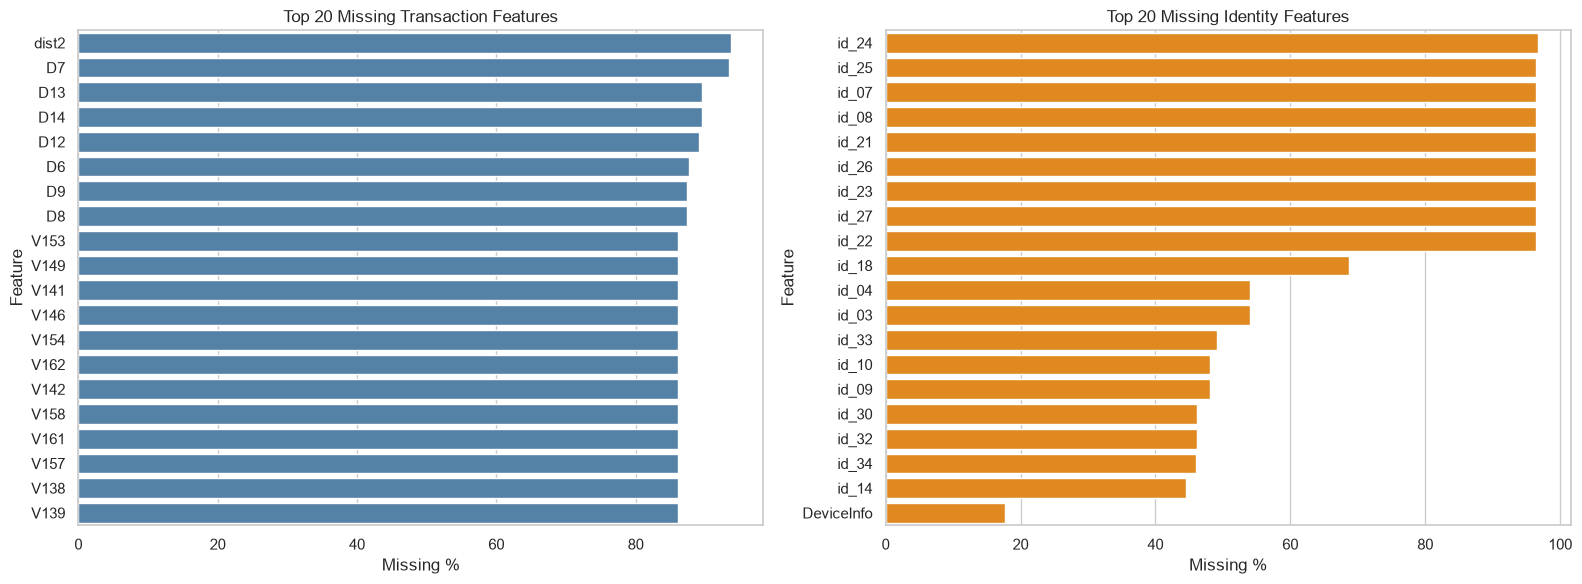

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=transaction_missing.head(20), y="Feature", x="Missing %", ax=axes[0], color="steelblue")
axes[0].set_title("Top 20 Missing Transaction Features")
sns.barplot(data=identity_missing.head(20), y="Feature", x="Missing %", ax=axes[1], color="darkorange")
axes[1].set_title("Top 20 Missing Identity Features")
plt.tight_layout()
plt.show()

**Interpretation:** Missing information is substantial, especially in selected transaction and identity fields. No values are filled and no columns are removed. Later preprocessing must decide how to handle missingness using training data only.

## 9. Duplicate Analysis

In [13]:
print("Transaction duplicate rows:", int(train_transaction.duplicated().sum()))
print("Identity duplicate rows:", int(train_identity.duplicated().sum()))
print("Transaction duplicate TransactionIDs:", int(train_transaction["TransactionID"].duplicated().sum()))
print("Identity duplicate TransactionIDs:", int(train_identity["TransactionID"].duplicated().sum()))

Transaction duplicate rows: 0


Identity duplicate rows: 0
Transaction duplicate TransactionIDs: 0
Identity duplicate TransactionIDs: 0


**Interpretation:** Duplicate full rows and duplicate keys are checked but not deleted. If duplicates appear later, they may affect joining and model evaluation.

## 10. Cardinality Analysis

For this initial audit, low cardinality means ≤10 unique values, medium means 11–100, and high means >100. This is only a descriptive classification.

In [14]:
def cardinality_table(df):
    columns = df.select_dtypes(include=["object", "category"]).columns
    table = pd.DataFrame({
        "Feature": columns,
        "Data Type": [str(df[c].dtype) for c in columns],
        "Unique Values": [df[c].nunique(dropna=False) for c in columns]
    })
    table["Cardinality"] = pd.cut(table["Unique Values"], bins=[-1, 10, 100, np.inf], labels=["Low", "Medium", "High"])
    return table.sort_values("Unique Values", ascending=False)

transaction_cardinality = cardinality_table(train_transaction)
identity_cardinality = cardinality_table(train_identity)
print("Transaction categorical cardinality:")
display(transaction_cardinality)
print("Identity categorical cardinality:")
display(identity_cardinality)

C:\Users\HP\AppData\Local\Temp\ipykernel_24364\2147524434.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns = df.select_dtypes(include=["object", "category"]).columns


Transaction categorical cardinality:


C:\Users\HP\AppData\Local\Temp\ipykernel_24364\2147524434.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns = df.select_dtypes(include=["object", "category"]).columns


,Feature,Data Type,Unique Values,Cardinality
4,R_emaildomain,str,61,Medium
3,P_emaildomain,str,60,Medium
1,card4,str,5,Low
0,ProductCD,str,5,Low
2,card6,str,5,Low
8,M4,str,4,Low
5,M1,str,3,Low
6,M2,str,3,Low
7,M3,str,3,Low
9,M5,str,3,Low


Identity categorical cardinality:


,Feature,Data Type,Unique Values,Cardinality
16,DeviceInfo,str,1787,High
9,id_33,str,261,High
8,id_31,str,131,High
7,id_30,str,76,Medium
10,id_34,str,5,Low
3,id_23,str,4,Low
1,id_15,str,4,Low
5,id_28,str,3,Low
4,id_27,str,3,Low
12,id_36,str,3,Low


**Interpretation:** High-cardinality fields may require careful later encoding. No encoding is performed in this phase.

## 11. Initial Data Quality Assessment

In [15]:
transaction_constant = train_transaction.nunique(dropna=False) == 1
identity_constant = train_identity.nunique(dropna=False) == 1
transaction_identifier_candidates = [c for c in train_transaction.columns if c.lower() == "transactionid" or c.lower().startswith("card") or c.lower().endswith("id")]
identity_identifier_candidates = [c for c in train_identity.columns if c.lower() == "transactionid" or c.lower().startswith("id_") or "device" in c.lower()]

print("Constant transaction features:", train_transaction.columns[transaction_constant].tolist())
print("Constant identity features:", train_identity.columns[identity_constant].tolist())
print("Potential transaction identifiers:", transaction_identifier_candidates)
print("Potential identity/device identifiers:", identity_identifier_candidates)
print("\nPotential risks identified:")
print("- Missing data: substantial missingness requires later, train-only handling.")
print("- High cardinality: some identity/device fields may need careful encoding later.")
print("- Identifier leakage: ID-like fields must be investigated before modeling.")
print("- Memory: the transaction file is wide and requires memory-aware processing.")
print("- Duplicate risk: currently no duplicate rows or keys were observed." )

Constant transaction features: []
Constant identity features: []
Potential transaction identifiers: ['TransactionID', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6']
Potential identity/device identifiers: ['TransactionID', 'id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']

Potential risks identified:
- Missing data: substantial missingness requires later, train-only handling.
- High cardinality: some identity/device fields may need careful encoding later.
- Identifier leakage: ID-like fields must be investigated before modeling.
- Memory: the transaction file is wide and requires memory-aware processing.
- Duplicate risk: currently no duplicate rows or keys were obs

**Identifier assessment:** `TransactionID` is primarily a join key, not automatically a useful predictive feature. Card and identity/device fields may contain useful behavioral information, but their predictive value and leakage risk require later investigation. No identifier is removed now.

## 12. Phase 1 Conclusion

### Phase 1 — Final Data Inspection Report

1. **Dataset Overview:** Both original CSV datasets are readable and contain the expected transaction and identity information.
2. **Transaction Dataset:** The dataset is wide, contains numerical and categorical fields, and has substantial missingness.
3. **Identity Dataset:** Identity/device fields are partially populated and include high-cardinality columns.
4. **Target Analysis:** `isFraud` is binary with observed values 0 and 1; the class distribution is imbalanced.
5. **TransactionID Analysis:** The key exists in both datasets, is non-missing and unique in each, and can be considered for a controlled future join.
6. **Missing Values:** Missingness is a major data-quality characteristic; no filling or deletion was performed.
7. **Duplicates:** Duplicate rows and duplicate keys were checked and not deleted.
8. **Cardinality:** Categorical cardinality was measured descriptively; no encoding was performed.
9. **Constant Features:** Constant fields were checked and not removed.
10. **Potential Identifier Features:** ID-like fields were identified for later investigation, not automatically discarded.
11. **Integration Readiness:** The datasets are structurally ready for a carefully validated future merge, but the merge is not performed here.
12. **Potential Risks:** Missing data, class imbalance, high cardinality, identifier leakage, memory usage, and possible distribution differences between records with and without identity information.
13. **Recommended Next Step:** After explicit approval, create `02_data_integration.ipynb` and perform a controlled merge using `TransactionID`, with row-count and key-integrity checks.

**Decision:** Stop after Phase 1. Do not start data integration or any modeling phase yet.